# Reusable Exploratory Data Analysis (EDA) Template

## Objective
This notebook provides a reusable workflow for performing
Exploratory Data Analysis (EDA) on different datasets.

## Analysis Steps
- Dataset Overview
- Data Quality Checks
- Missing Value Analysis
- Duplicate Detection
- Data Cleaning
- Statistical Analysis
- Data Visualization
- Key Insights

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [7]:
file_path = r"D:\world_population.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (234, 17)


,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
0,36,AFG,Afghanistan,Kabul,Asia,41128771.0,38972230.0,33753499.0,28189672.0,19542982.0,10694796.0,12486631.0,10752971.0,652230.0,63.0587,1.0257,0.52
1,138,ALB,Albania,Tirana,Europe,2842321.0,2866849.0,2882481.0,2913399.0,3182021.0,3295066.0,2941651.0,2324731.0,28748.0,98.8702,0.9957,0.04
2,34,DZA,Algeria,Algiers,Africa,44903225.0,43451666.0,39543154.0,35856344.0,30774621.0,25518074.0,18739378.0,13795915.0,2381741.0,18.8531,1.0164,0.56
3,213,ASM,American Samoa,Pago Pago,Oceania,44273.0,46189.0,51368.0,54849.0,58230.0,47818.0,32886.0,27075.0,199.0,222.4774,0.9831,0.00
4,203,AND,Andorra,Andorra la Vella,Europe,79824.0,77700.0,71746.0,71519.0,66097.0,53569.0,35611.0,19860.0,468.0,170.5641,1.0100,0.00


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Rank                         234 non-null    int64  
 1   CCA3                         234 non-null    str    
 2   Country                      234 non-null    str    
 3   Capital                      234 non-null    str    
 4   Continent                    234 non-null    str    
 5   2022 Population              230 non-null    float64
 6   2020 Population              233 non-null    float64
 7   2015 Population              230 non-null    float64
 8   2010 Population              227 non-null    float64
 9   2000 Population              227 non-null    float64
 10  1990 Population              229 non-null    float64
 11  1980 Population              229 non-null    float64
 12  1970 Population              230 non-null    float64
 13  Area (km²)                   23

## 1. Dataset Overview

In this section, we will understand the structure, size, and basic information of the World Population dataset.

In [12]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Name:")
print(df.columns.tolist())

display(df.head())

display(df.tail())

display(df.sample(5))


Number of Rows: 234
Number of Columns: 17

Column Name:
['Rank', 'CCA3', 'Country', 'Capital', 'Continent', '2022 Population', '2020 Population', '2015 Population', '2010 Population', '2000 Population', '1990 Population', '1980 Population', '1970 Population', 'Area (km²)', 'Density (per km²)', 'Growth Rate', 'World Population Percentage']


,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
0,36,AFG,Afghanistan,Kabul,Asia,41128771.0,38972230.0,33753499.0,28189672.0,19542982.0,10694796.0,12486631.0,10752971.0,652230.0,63.0587,1.0257,0.52
1,138,ALB,Albania,Tirana,Europe,2842321.0,2866849.0,2882481.0,2913399.0,3182021.0,3295066.0,2941651.0,2324731.0,28748.0,98.8702,0.9957,0.04
2,34,DZA,Algeria,Algiers,Africa,44903225.0,43451666.0,39543154.0,35856344.0,30774621.0,25518074.0,18739378.0,13795915.0,2381741.0,18.8531,1.0164,0.56
3,213,ASM,American Samoa,Pago Pago,Oceania,44273.0,46189.0,51368.0,54849.0,58230.0,47818.0,32886.0,27075.0,199.0,222.4774,0.9831,0.00
4,203,AND,Andorra,Andorra la Vella,Europe,79824.0,77700.0,71746.0,71519.0,66097.0,53569.0,35611.0,19860.0,468.0,170.5641,1.0100,0.00


,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
229,226,WLF,Wallis and Futuna,Mata-Utu,Oceania,11572.0,11655.0,12182.0,13142.0,14723.0,13454.0,11315.0,9377.0,142.0,81.4930,0.9953,0.00
230,172,ESH,Western Sahara,El Aaiún,Africa,575986.0,556048.0,491824.0,413296.0,270375.0,178529.0,116775.0,76371.0,266000.0,2.1654,1.0184,0.01
231,46,YEM,Yemen,Sanaa,Asia,33696614.0,32284046.0,28516545.0,24743946.0,18628700.0,13375121.0,9204938.0,6843607.0,527968.0,63.8232,1.0217,0.42
232,63,ZMB,Zambia,Lusaka,Africa,20017675.0,18927715.0,NaN,13792086.0,9891136.0,7686401.0,5720438.0,4281671.0,752612.0,26.5976,1.0280,0.25
233,74,ZWE,Zimbabwe,Harare,Africa,16320537.0,15669666.0,14154937.0,12839771.0,11834676.0,10113893.0,7049926.0,5202918.0,390757.0,41.7665,1.0204,0.20


,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
19,81,BEL,Belgium,Brussels,Europe,11655930.0,11561717.0,11248303.0,10877947.0,10264343.0,9959560.0,9828986.0,9629376.0,30528.0,381.8111,1.0038,0.15
7,201,ATG,Antigua and Barbuda,Saint John’s,North America,93763.0,92664.0,89941.0,85695.0,75055.0,63328.0,64888.0,64516.0,442.0,212.1335,1.0058,0.00
65,209,FRO,Faroe Islands,Tórshavn,Europe,53090.0,52415.0,48816.0,48410.0,45660.0,47479.0,43054.0,38416.0,1393.0,38.1120,1.0038,0.00
67,118,FIN,Finland,Helsinki,Europe,5540745.0,5529468.0,5479461.0,5363271.0,5176209.0,4986545.0,4779418.0,4606621.0,338424.0,16.3722,1.0009,0.07
78,208,GRL,Greenland,Nuuk,North America,56466.0,56026.0,55895.0,56351.0,56184.0,55599.0,50106.0,45434.0,2166086.0,0.0261,1.0040,0.00


In [13]:
display(df.describe())

display(df.describe(include="all"))

,Rank,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
count,234.000000,2.300000e+02,2.330000e+02,2.300000e+02,2.270000e+02,2.270000e+02,2.290000e+02,2.290000e+02,2.300000e+02,2.320000e+02,230.000000,232.000000,234.000000
mean,117.500000,3.463225e+07,3.360071e+07,3.206600e+07,3.027016e+07,2.684050e+07,1.933046e+07,1.628288e+07,1.586650e+07,5.816637e+05,456.811652,1.009553,0.427051
std,67.694165,1.378892e+08,1.358732e+08,1.315071e+08,1.260742e+08,1.133525e+08,8.130962e+07,6.934547e+07,6.835586e+07,1.769133e+06,2083.740364,0.013390,1.714977
min,1.000000,5.100000e+02,5.200000e+02,5.640000e+02,5.960000e+02,6.510000e+02,7.000000e+02,7.330000e+02,7.520000e+02,1.000000e+00,0.026100,0.912000,0.000000
25%,59.250000,4.197385e+05,4.064710e+05,3.942950e+05,3.827265e+05,3.294700e+05,2.619280e+05,2.237520e+05,1.458805e+05,2.567250e+03,36.598125,1.001925,0.010000
50%,117.500000,5.762857e+06,5.456681e+06,5.244415e+06,4.889741e+06,4.491202e+06,3.785847e+06,3.135123e+06,2.511718e+06,7.714100e+04,95.346750,1.007900,0.070000
75%,175.750000,2.265372e+07,2.152263e+07,1.973085e+07,1.682585e+07,1.562547e+07,1.188276e+07,9.817257e+06,8.817329e+06,4.146432e+05,236.884000,1.016650,0.280000
max,234.000000,1.425887e+09,1.424930e+09,1.393715e+09,1.348191e+09,1.264099e+09,1.153704e+09,9.823725e+08,8.225344e+08,1.709824e+07,23172.266700,1.069100,17.880000


,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
count,234.000000,234,234,234,234,2.300000e+02,2.330000e+02,2.300000e+02,2.270000e+02,2.270000e+02,2.290000e+02,2.290000e+02,2.300000e+02,2.320000e+02,230.000000,232.000000,234.000000
unique,NaN,234,234,234,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,AFG,Afghanistan,Kabul,Africa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,1,1,57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,117.500000,NaN,NaN,NaN,NaN,3.463225e+07,3.360071e+07,3.206600e+07,3.027016e+07,2.684050e+07,1.933046e+07,1.628288e+07,1.586650e+07,5.816637e+05,456.811652,1.009553,0.427051
std,67.694165,NaN,NaN,NaN,NaN,1.378892e+08,1.358732e+08,1.315071e+08,1.260742e+08,1.133525e+08,8.130962e+07,6.934547e+07,6.835586e+07,1.769133e+06,2083.740364,0.013390,1.714977
min,1.000000,NaN,NaN,NaN,NaN,5.100000e+02,5.200000e+02,5.640000e+02,5.960000e+02,6.510000e+02,7.000000e+02,7.330000e+02,7.520000e+02,1.000000e+00,0.026100,0.912000,0.000000
25%,59.250000,NaN,NaN,NaN,NaN,4.197385e+05,4.064710e+05,3.942950e+05,3.827265e+05,3.294700e+05,2.619280e+05,2.237520e+05,1.458805e+05,2.567250e+03,36.598125,1.001925,0.010000
50%,117.500000,NaN,NaN,NaN,NaN,5.762857e+06,5.456681e+06,5.244415e+06,4.889741e+06,4.491202e+06,3.785847e+06,3.135123e+06,2.511718e+06,7.714100e+04,95.346750,1.007900,0.070000
75%,175.750000,NaN,NaN,NaN,NaN,2.265372e+07,2.152263e+07,1.973085e+07,1.682585e+07,1.562547e+07,1.188276e+07,9.817257e+06,8.817329e+06,4.146432e+05,236.884000,1.016650,0.280000


## 2. Missing Values Analysis



In [14]:
missing_count = df.isnull().sum()



In [15]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

In [16]:
missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

In [17]:
missing_report = missing_report[missing_report["Missing Count"] > 0]

display(missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Count,Missing Percentage
2010 Population,7,2.991453
2000 Population,7,2.991453
1990 Population,5,2.136752
1980 Population,5,2.136752
1970 Population,4,1.709402
2022 Population,4,1.709402
2015 Population,4,1.709402
Density (per km²),4,1.709402
Area (km²),2,0.854701
Growth Rate,2,0.854701


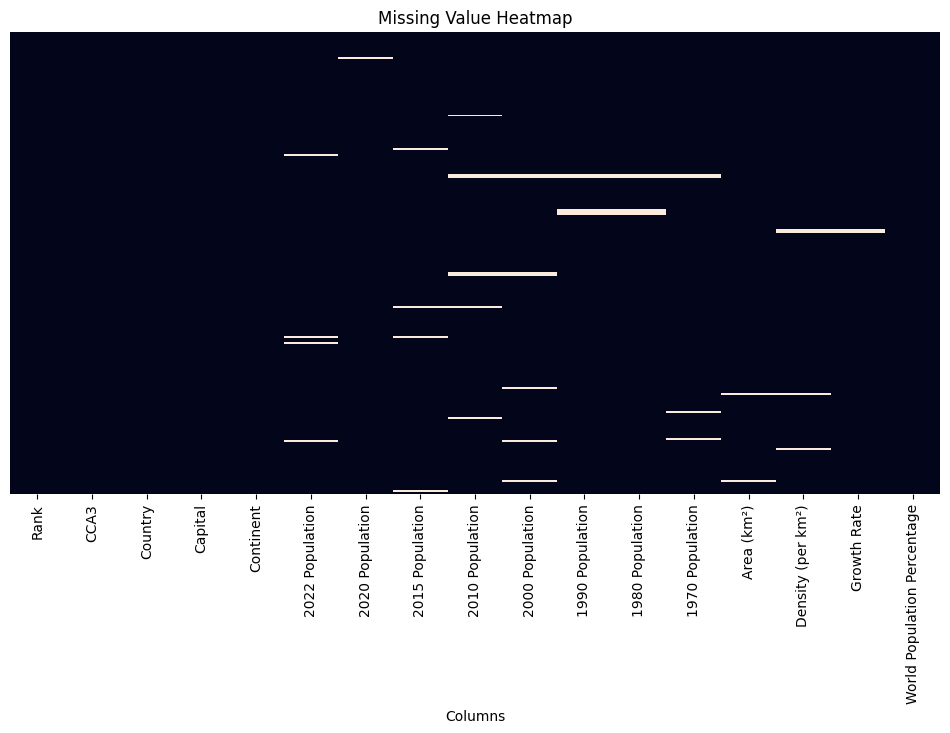

In [18]:
plt.figure(figsize=(12,6))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title("Missing Value Heatmap")
plt.xlabel("Columns")
plt.show()

In [20]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [21]:
unique_counts = df.nunique()

display(unique_counts.to_frame(name="Unique Values"))

,Unique Values
Rank,234
CCA3,234
Country,234
Capital,234
Continent,6
2022 Population,230
2020 Population,233
2015 Population,230
2010 Population,227
2000 Population,227


In [ ]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

Original Shape: (234, 17)
Cleaned Shape: (234, 17)


In [23]:
print("Missing Values Before Cleaning:")
print(df.isnull().sum().sum())

print("\nMissing Values After Removing Duplicates:")
print(df_clean.isnull().sum().sum())

Missing Values Before Cleaning:
45

Missing Values After Removing Duplicates:
45


In [24]:
display(df_clean.dtypes)

Rank                             int64
CCA3                               str
Country                            str
Capital                            str
Continent                          str
2022 Population                float64
2020 Population                float64
2015 Population                float64
2010 Population                float64
2000 Population                float64
1990 Population                float64
1980 Population                float64
1970 Population                float64
Area (km²)                     float64
Density (per km²)              float64
Growth Rate                    float64
World Population Percentage    float64
dtype: object

## 3. Statistical Analysis

In [25]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numeric_cols.tolist())

Numerical Columns:
['Rank', '2022 Population', '2020 Population', '2015 Population', '2010 Population', '2000 Population', '1990 Population', '1980 Population', '1970 Population', 'Area (km²)', 'Density (per km²)', 'Growth Rate', 'World Population Percentage']


In [26]:
display(df_clean[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Rank,234.0,1.175000e+02,6.769417e+01,1.0000,59.250000,1.175000e+02,1.757500e+02,2.340000e+02
2022 Population,230.0,3.463225e+07,1.378892e+08,510.0000,419738.500000,5.762857e+06,2.265372e+07,1.425887e+09
2020 Population,233.0,3.360071e+07,1.358732e+08,520.0000,406471.000000,5.456681e+06,2.152263e+07,1.424930e+09
2015 Population,230.0,3.206600e+07,1.315071e+08,564.0000,394295.000000,5.244415e+06,1.973085e+07,1.393715e+09
2010 Population,227.0,3.027016e+07,1.260742e+08,596.0000,382726.500000,4.889741e+06,1.682585e+07,1.348191e+09
2000 Population,227.0,2.684050e+07,1.133525e+08,651.0000,329470.000000,4.491202e+06,1.562547e+07,1.264099e+09
1990 Population,229.0,1.933046e+07,8.130962e+07,700.0000,261928.000000,3.785847e+06,1.188276e+07,1.153704e+09
1980 Population,229.0,1.628288e+07,6.934547e+07,733.0000,223752.000000,3.135123e+06,9.817257e+06,9.823725e+08
1970 Population,230.0,1.586650e+07,6.835586e+07,752.0000,145880.500000,2.511718e+06,8.817329e+06,8.225344e+08
Area (km²),232.0,5.816637e+05,1.769133e+06,1.0000,2567.250000,7.714100e+04,4.146432e+05,1.709824e+07


In [27]:
for col in numeric_cols:
    print(f"\nColumn: {col}")
    print("Mean:", df_clean[col].mean())
    print("Median:", df_clean[col].median())
    print("Mode:", df_clean[col].mode().iloc[0] if not df_clean[col].mode().empty else "No mode")


Column: Rank
Mean: 117.5
Median: 117.5
Mode: 1

Column: 2022 Population
Mean: 34632250.87826087
Median: 5762857.0
Mode: 510.0

Column: 2020 Population
Mean: 33600710.9527897
Median: 5456681.0
Mode: 520.0

Column: 2015 Population
Mean: 32066004.156521738
Median: 5244415.0
Mode: 564.0

Column: 2010 Population
Mean: 30270164.475770924
Median: 4889741.0
Mode: 596.0

Column: 2000 Population
Mean: 26840495.25550661
Median: 4491202.0
Mode: 651.0

Column: 1990 Population
Mean: 19330463.930131003
Median: 3785847.0
Mode: 700.0

Column: 1980 Population
Mean: 16282884.781659389
Median: 3135123.0
Mode: 733.0

Column: 1970 Population
Mean: 15866499.126086956
Median: 2511718.0
Mode: 752.0

Column: Area (km²)
Mean: 581663.7456896552
Median: 77141.0
Mode: 21.0

Column: Density (per km²)
Mean: 456.81165173913047
Median: 95.34675
Mode: 0.0261

Column: Growth Rate
Mean: 1.0095534482758621
Median: 1.0079
Mode: 1.0038

Column: World Population Percentage
Mean: 0.42705128205128207
Median: 0.07
Mode: 0.0


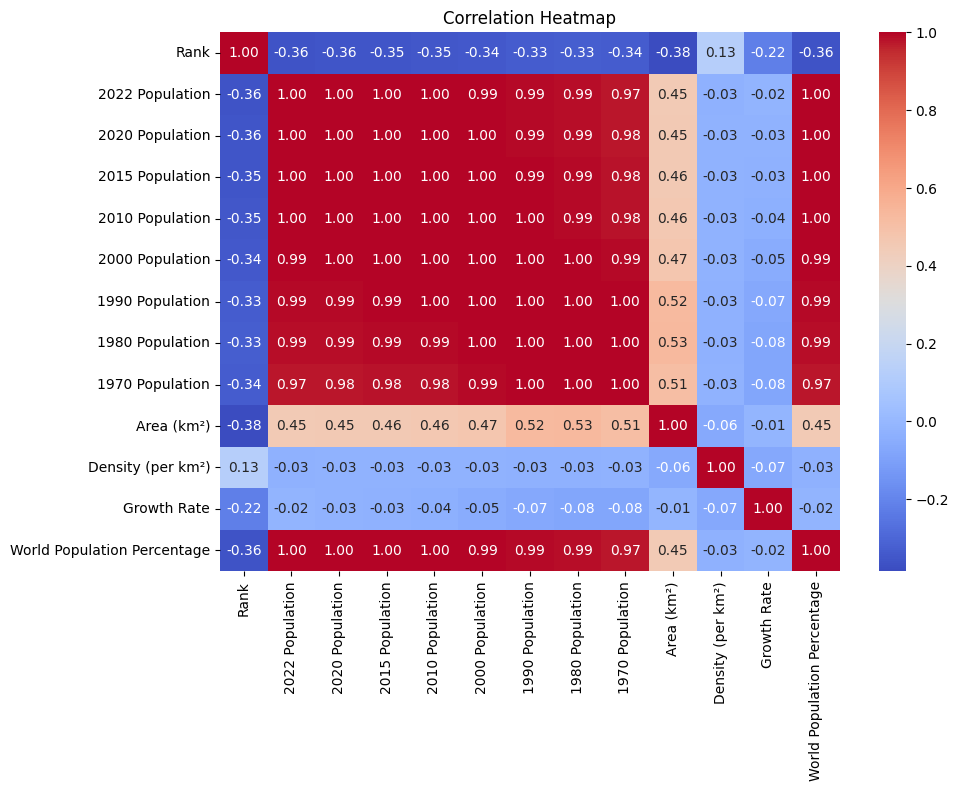

In [51]:
correlation = df_clean[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [30]:
print(df_clean.columns.tolist())

['Rank', 'CCA3', 'Country', 'Capital', 'Continent', '2022 Population', '2020 Population', '2015 Population', '2010 Population', '2000 Population', '1990 Population', '1980 Population', '1970 Population', 'Area (km²)', 'Density (per km²)', 'Growth Rate', 'World Population Percentage']


In [31]:
continent_population = df_clean.groupby("Continent")["2022 Population"].sum()

display(continent_population.sort_values(ascending=False))

Continent
Asia             4.720042e+09
Africa           1.425529e+09
Europe           7.377132e+08
North America    6.002961e+08
South America    4.368166e+08
Oceania          4.502050e+07
Name: 2022 Population, dtype: float64

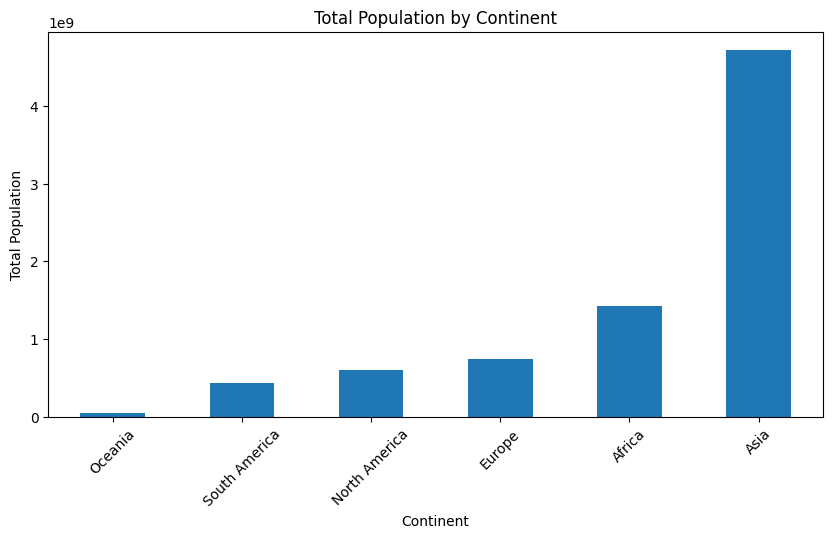

In [32]:
continent_population.sort_values().plot(
    kind="bar",
    figsize=(10, 5),
    title="Total Population by Continent"
)

plt.xlabel("Continent")
plt.ylabel("Total Population")
plt.xticks(rotation=45)
plt.show()

In [33]:
continent_summary = df_clean.groupby("Continent")["2022 Population"].agg(
    ["sum", "mean", "min", "max", "count"]
)

display(continent_summary)

,sum,mean,min,max,count
Continent,,,,,
Africa,1.425529e+09,2.545588e+07,107118.0,2.185412e+08,56
Asia,4.720042e+09,9.632739e+07,449002.0,1.425887e+09,49
Europe,7.377132e+08,1.505537e+07,510.0,1.447133e+08,49
North America,6.002961e+08,1.500740e+07,4390.0,3.382899e+08,40
Oceania,4.502050e+07,2.046386e+06,1871.0,2.617741e+07,22
South America,4.368166e+08,3.120119e+07,3780.0,2.153135e+08,14


In [34]:
print(df_clean.columns.tolist())

['Rank', 'CCA3', 'Country', 'Capital', 'Continent', '2022 Population', '2020 Population', '2015 Population', '2010 Population', '2000 Population', '1990 Population', '1980 Population', '1970 Population', 'Area (km²)', 'Density (per km²)', 'Growth Rate', 'World Population Percentage']


In [35]:
# filtering
top_10_countries = df_clean.nlargest(
    10,"2022 Population"
)

display(top_10_countries[["Country","2022 Population"]])

,Country,2022 Population
41,China,1.425887e+09
92,India,1.417173e+09
221,United States,3.382899e+08
93,Indonesia,2.755013e+08
156,Pakistan,2.358249e+08
149,Nigeria,2.185412e+08
27,Brazil,2.153135e+08
16,Bangladesh,1.711864e+08
171,Russia,1.447133e+08
131,Mexico,1.275041e+08


In [36]:
sorted_population = df_clean.sort_values(
    by="2022 Population",
    ascending=False
)

display(sorted_population[["Country", "2022 Population"]].head(10))

,Country,2022 Population
41,China,1.425887e+09
92,India,1.417173e+09
221,United States,3.382899e+08
93,Indonesia,2.755013e+08
156,Pakistan,2.358249e+08
149,Nigeria,2.185412e+08
27,Brazil,2.153135e+08
16,Bangladesh,1.711864e+08
171,Russia,1.447133e+08
131,Mexico,1.275041e+08


In [39]:
#conditional filtering

high_population = df_clean[
    df_clean["2022 Population"] > 100_000_000
]

display(high_population[["Country","2022 Population"]])

,Country,2022 Population
16,Bangladesh,1.711864e+08
27,Brazil,2.153135e+08
41,China,1.425887e+09
57,Egypt,1.109901e+08
63,Ethiopia,1.233799e+08
92,India,1.417173e+09
93,Indonesia,2.755013e+08
102,Japan,1.239517e+08
131,Mexico,1.275041e+08
149,Nigeria,2.185412e+08


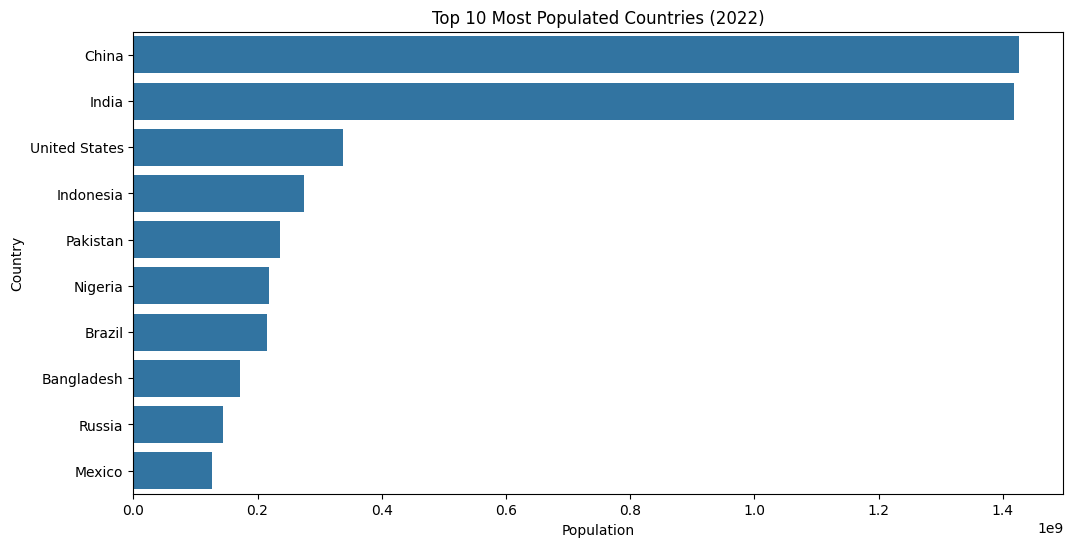

In [40]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_countries,
    x="2022 Population",
    y="Country"
)

plt.title("Top 10 Most Populated Countries (2022)")
plt.xlabel("Population")
plt.ylabel("Country")
plt.show()

## 4. Data Visualization

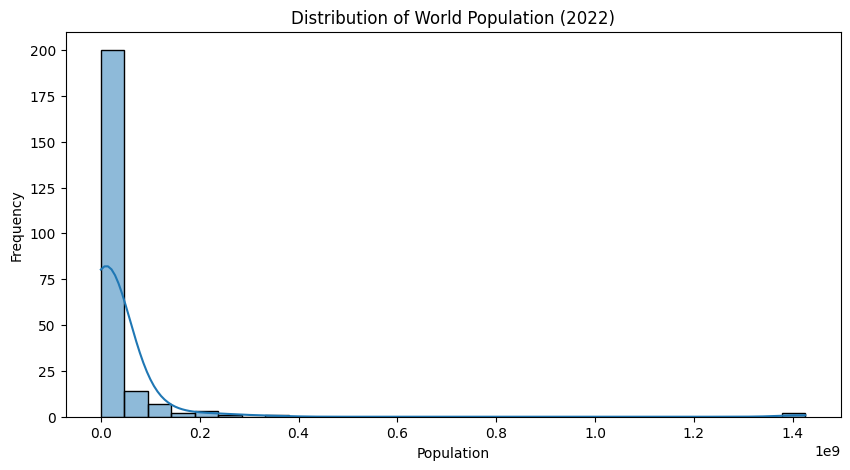

In [41]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="2022 Population",
    bins=30,
    kde=True
)
plt.title("Distribution of World Population (2022)")
plt.xlabel("Population")
plt.ylabel("Frequency")
plt.show()

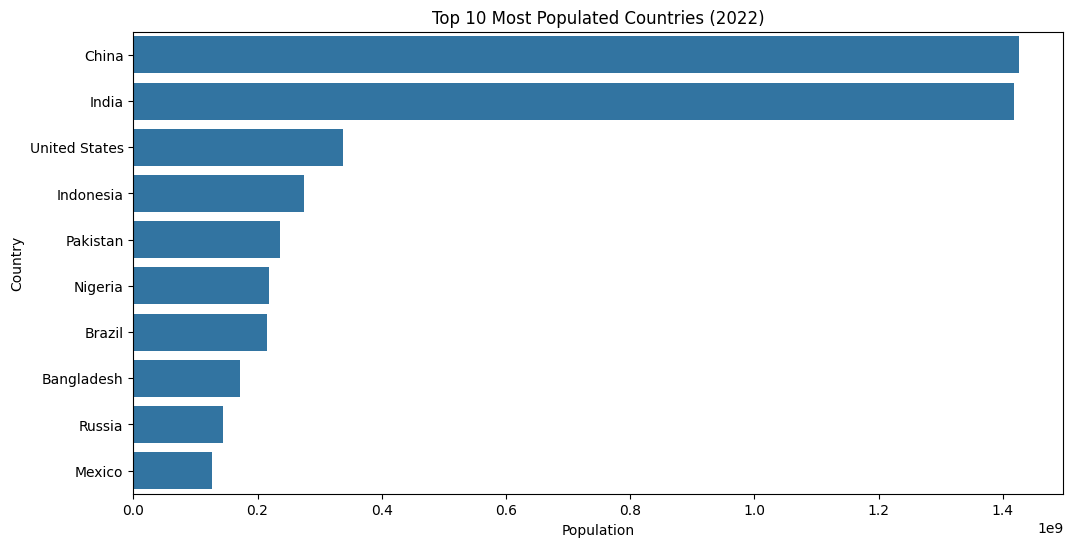

In [42]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_countries,
    x="2022 Population",
    y="Country"
)

plt.title("Top 10 Most Populated Countries (2022)")
plt.xlabel("Population")
plt.ylabel("Country")
plt.show()

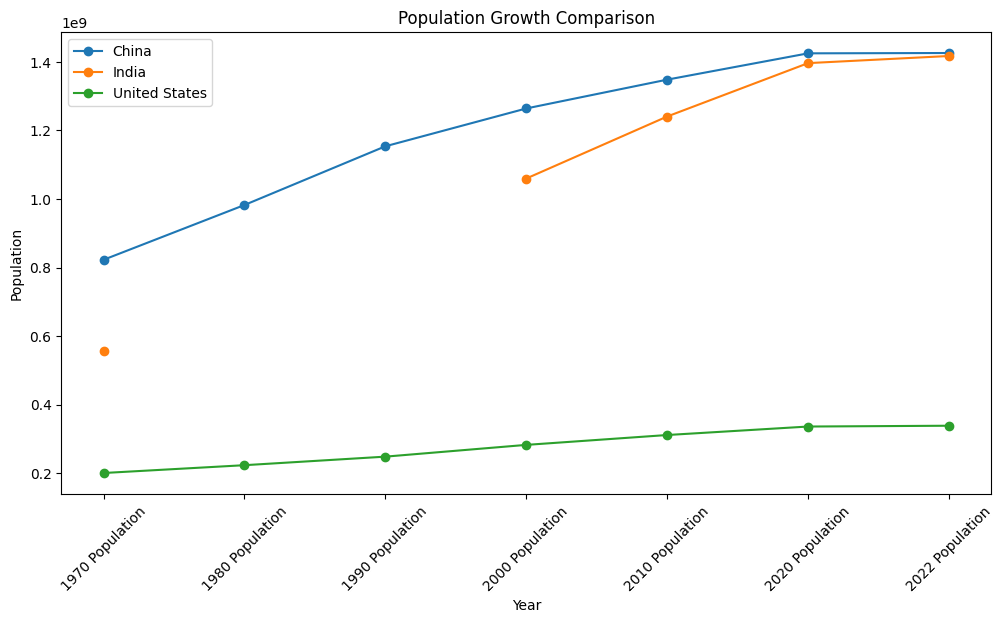

In [43]:
population_years = [
    "1970 Population",
    "1980 Population",
    "1990 Population",
    "2000 Population",
    "2010 Population",
    "2020 Population",
    "2022 Population"
]

countries_to_compare = ["India", "China", "United States"]

country_data = df_clean[
    df_clean["Country"].isin(countries_to_compare)
]

plt.figure(figsize=(12, 6))

for _, row in country_data.iterrows():
    plt.plot(
        population_years,
        row[population_years],
        marker="o",
        label=row["Country"]
    )

plt.title("Population Growth Comparison")
plt.xlabel("Year")
plt.ylabel("Population")
plt.xticks(rotation=45)
plt.legend()
plt.show()

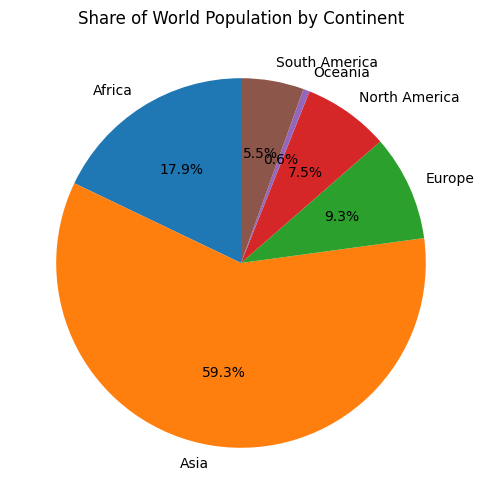

In [45]:
continent_population = (
    df_clean.groupby("Continent")["2022 Population"].sum()
)

plt.figure(figsize=(6, 6))

plt.pie(
    continent_population,
    labels=continent_population.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Share of World Population by Continent")
plt.show()

## 5. Key Insights and Conclusion

### Key Insights
- Analyzed the distribution of population across countries.
- Identified the most populated countries.
- Compared population growth across selected years.
- Examined the contribution of different continents to world population.

### Conclusion
Exploratory Data Analysis helped us understand the structure, quality, distribution, and patterns of the World Population dataset.

## 6. Reusable EDA Functions

In [46]:
def load_dataset(file_path):
    try:
        data = pd.read_csv(file_path)
        print("Dataset loaded successfully!")
        print("Shape:", data.shape)
        return data

    except FileNotFoundError:
        print("Error: File not found. Check the file path.")
        return None

    except Exception as e:
        print("Error:", e)
        return None

In [47]:
def dataset_overview(data):
    print("Dataset Shape:", data.shape)

    print("\nColumn Names:")
    print(data.columns.tolist())

    print("\nDataset Information:")
    data.info()

    print("\nStatistical Summary:")
    display(data.describe(include="all"))

In [48]:
def missing_values_report(data):
    report = pd.DataFrame({
        "Missing Count": data.isnull().sum(),
        "Missing Percentage": data.isnull().mean() * 100
    })

    return report.sort_values(
        by="Missing Percentage",
        ascending=False
    )

In [49]:
df_test = load_dataset(r"D:\world_population.csv")

if df_test is not None:
    dataset_overview(df_test)

    display(missing_values_report(df_test))

Dataset loaded successfully!
Shape: (234, 17)
Dataset Shape: (234, 17)

Column Names:
['Rank', 'CCA3', 'Country', 'Capital', 'Continent', '2022 Population', '2020 Population', '2015 Population', '2010 Population', '2000 Population', '1990 Population', '1980 Population', '1970 Population', 'Area (km²)', 'Density (per km²)', 'Growth Rate', 'World Population Percentage']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Rank                         234 non-null    int64  
 1   CCA3                         234 non-null    str    
 2   Country                      234 non-null    str    
 3   Capital                      234 non-null    str    
 4   Continent                    234 non-null    str    
 5   2022 Population              230 non-null    float64
 6   2020 Population              233 non-null   

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
count,234.000000,234,234,234,234,2.300000e+02,2.330000e+02,2.300000e+02,2.270000e+02,2.270000e+02,2.290000e+02,2.290000e+02,2.300000e+02,2.320000e+02,230.000000,232.000000,234.000000
unique,NaN,234,234,234,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,AFG,Afghanistan,Kabul,Africa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,1,1,57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,117.500000,NaN,NaN,NaN,NaN,3.463225e+07,3.360071e+07,3.206600e+07,3.027016e+07,2.684050e+07,1.933046e+07,1.628288e+07,1.586650e+07,5.816637e+05,456.811652,1.009553,0.427051
std,67.694165,NaN,NaN,NaN,NaN,1.378892e+08,1.358732e+08,1.315071e+08,1.260742e+08,1.133525e+08,8.130962e+07,6.934547e+07,6.835586e+07,1.769133e+06,2083.740364,0.013390,1.714977
min,1.000000,NaN,NaN,NaN,NaN,5.100000e+02,5.200000e+02,5.640000e+02,5.960000e+02,6.510000e+02,7.000000e+02,7.330000e+02,7.520000e+02,1.000000e+00,0.026100,0.912000,0.000000
25%,59.250000,NaN,NaN,NaN,NaN,4.197385e+05,4.064710e+05,3.942950e+05,3.827265e+05,3.294700e+05,2.619280e+05,2.237520e+05,1.458805e+05,2.567250e+03,36.598125,1.001925,0.010000
50%,117.500000,NaN,NaN,NaN,NaN,5.762857e+06,5.456681e+06,5.244415e+06,4.889741e+06,4.491202e+06,3.785847e+06,3.135123e+06,2.511718e+06,7.714100e+04,95.346750,1.007900,0.070000
75%,175.750000,NaN,NaN,NaN,NaN,2.265372e+07,2.152263e+07,1.973085e+07,1.682585e+07,1.562547e+07,1.188276e+07,9.817257e+06,8.817329e+06,4.146432e+05,236.884000,1.016650,0.280000


,Missing Count,Missing Percentage
2010 Population,7,2.991453
2000 Population,7,2.991453
1990 Population,5,2.136752
1980 Population,5,2.136752
1970 Population,4,1.709402
2015 Population,4,1.709402
2022 Population,4,1.709402
Density (per km²),4,1.709402
Growth Rate,2,0.854701
Area (km²),2,0.854701


In [50]:
file_path = r"D:\world_population.csv"

df = pd.read_csv(file_path)

display(df.head())

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
0,36,AFG,Afghanistan,Kabul,Asia,41128771.0,38972230.0,33753499.0,28189672.0,19542982.0,10694796.0,12486631.0,10752971.0,652230.0,63.0587,1.0257,0.52
1,138,ALB,Albania,Tirana,Europe,2842321.0,2866849.0,2882481.0,2913399.0,3182021.0,3295066.0,2941651.0,2324731.0,28748.0,98.8702,0.9957,0.04
2,34,DZA,Algeria,Algiers,Africa,44903225.0,43451666.0,39543154.0,35856344.0,30774621.0,25518074.0,18739378.0,13795915.0,2381741.0,18.8531,1.0164,0.56
3,213,ASM,American Samoa,Pago Pago,Oceania,44273.0,46189.0,51368.0,54849.0,58230.0,47818.0,32886.0,27075.0,199.0,222.4774,0.9831,0.00
4,203,AND,Andorra,Andorra la Vella,Europe,79824.0,77700.0,71746.0,71519.0,66097.0,53569.0,35611.0,19860.0,468.0,170.5641,1.0100,0.00
